# 04 - Extension: neural network (MLP)
**Lead:** Nouf, with Ajwan.

We test whether a small feed-forward neural network can compete with the tree ensembles. It uses the same pipeline and the same time-series CV on the training data. **The test set is not used here** - it was used once in notebook 03.

In [1]:
# Setup: make the project root importable (works in Jupyter and in Colab
# after `%cd <repo>/notebooks`).
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.utils import *
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

def save(fig, name):
    """Save a figure to report/figures so it can go straight into the report."""
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=160)
    plt.show()

In [2]:
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor

train, _ = load_split()
X, y = xy(train)

# Neural networks need scaled inputs and one-hot codes -> "linear" preprocessing.
# The log target keeps the output scale small, which helps training.
mlp = TransformedTargetRegressor(
    regressor=pipeline(MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3,
                                    learning_rate_init=1e-3, max_iter=500,
                                    early_stopping=True, random_state=SEED)),
    func=np.log1p, inverse_func=np.expm1)

nn = pd.DataFrame([cv_scores("Neural network (MLP 64-32, log y)", mlp, X, y)])
nn.to_csv(RESULTS / "extension_nn_results.csv", index=False)

compare = pd.concat([pd.read_csv(RESULTS / "all_model_results.csv"), nn], ignore_index=True)
compare.sort_values("val_RMSE_mean")[["Model", "val_RMSE_mean", "val_RMSE_std",
                                       "val_R2_mean", "train_RMSE_mean", "fit_time_s"]]

,Model,val_RMSE_mean,val_RMSE_std,val_R2_mean,train_RMSE_mean,fit_time_s
0,Random Forest,79.445,19.328,0.743,11.475,2.774
1,Gradient Boosting,89.591,18.443,0.683,44.359,0.395
2,Decision Tree,95.433,21.538,0.642,0.165,0.029
3,Linear Regression,109.046,19.532,0.542,68.964,0.023
4,Ridge (alpha=1),109.117,19.597,0.542,68.966,0.015
5,Linear Regression (log y),113.527,30.754,0.511,65.206,0.022
6,k-NN (k=10),132.771,28.460,0.333,70.630,0.012
8,"Neural network (MLP 64-32, log y)",143.467,51.186,0.235,29.498,0.730
7,Mean baseline,180.623,42.739,-0.214,122.965,0.021


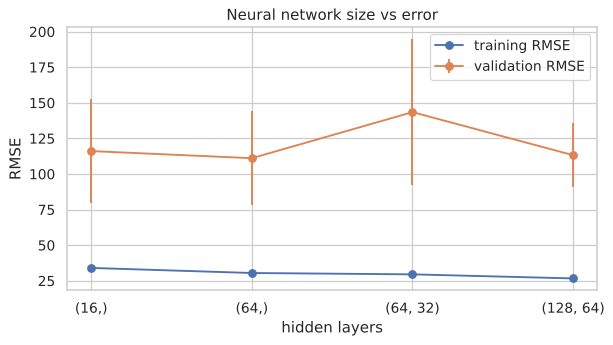

In [3]:
# effect of network size (training CV only)
rows = []
for layers in [(16,), (64,), (64, 32), (128, 64)]:
    m = TransformedTargetRegressor(
        regressor=pipeline(MLPRegressor(hidden_layer_sizes=layers, alpha=1e-3, max_iter=500,
                                        early_stopping=True, random_state=SEED)),
        func=np.log1p, inverse_func=np.expm1)
    rows.append(cv_scores(str(layers), m, X, y))
sizes = pd.DataFrame(rows)
sizes.to_csv(RESULTS / "extension_nn_sizes.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sizes["Model"], sizes["train_RMSE_mean"], "o-", label="training RMSE")
ax.errorbar(sizes["Model"], sizes["val_RMSE_mean"], yerr=sizes["val_RMSE_std"],
            fmt="o-", label="validation RMSE")
ax.set(xlabel="hidden layers", ylabel="RMSE", title="Neural network size vs error")
ax.legend()
save(fig, "fig13_nn_sizes.png")

### Discussion
- The MLP (64-32, log target) reached validation RMSE 143.5 ± 51.2, worse than linear regression (109.0) and far from the random forest (79.4). Its training RMSE is low (29.5), so it can fit the data but does not generalise across time.
- Network size does not help in a consistent way: (64,) gives 111.1, (128, 64) 113.2 and (64, 32) 143.5. The very large spread between folds shows the network is unstable when trained on the small early folds and sensitive to its settings and random seed.
- Conclusion: on this tabular data set, with about 14,000 rows and a strong time shift, the tree ensemble is more accurate, faster to tune and easier to explain than a neural network.
- Note: `early_stopping=True` holds out 10% of each training fold at random for stopping; this stays inside the training data, so the test set remains clean.